In [1]:
## Import all the necessary libraries etc.

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

In [2]:
## Check the tensor flow version 

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[]


In [3]:
## Load the dataset, check and clean for the corrupted/ non-JPEG files

data_dir = r"C:\Users\684536\tensorflow_datasets\downloads\cats_vs_dogs\down.micr.com_down_3_E_1_3E1C-ECDB-4869-83t5dL0AqEqZkh827kQD8ImFN3e1ro0VHHaobmSQAzSvk\PetImages"

num_deleted = 0
for folder in ("Cat", "Dog"):
    folder_path = os.path.join(data_dir, folder)
    for fname in os.listdir(folder_path):
        fpath = os.path.join(folder_path, fname)

        # Read the first few bytes; a genuine jpeg has 'jfif' near the start
        with open(fpath, "rb") as f:
            is_jpeg = b"JFIF" in f.peek(10)

        if not is_jpeg:
            os.remove(fpath)
            num_deleted += 1

print(f"Deleted {num_deleted} corrupted or non-JPEG files.")

Deleted 0 corrupted or non-JPEG files.


In [4]:
## Build a table of files with labels for cat and dog images
data_dir = r"C:\Users\684536\tensorflow_datasets\downloads\cats_vs_dogs\down.micr.com_down_3_E_1_3E1C-ECDB-4869-83t5dL0AqEqZkh827kQD8ImFN3e1ro0VHHaobmSQAzSvk\PetImages"

rows = []
for label, folder in enumerate(["Cat", "Dog"]):
    folder_path = os.path.join(data_dir, folder)   ## joining the directory and the folder 
    for fname in os.listdir(folder_path):          ## loop through the files
        rows.append({"path":os.path.join(folder_path, fname), "label":label})  ## Adds one row per file: its path and label (Cat = 0, Dog = 1)

df = pd.DataFrame(rows) ## Turns the list of rows into a table

print("Total images:", len(df)) ## Print the total number of images 
print(df["label"].value_counts())  ## Counts the images per label (0 = cat, 1 = dog) 
df.head()

Total images: 23424
label
0    11749
1    11675
Name: count, dtype: int64


,path,label
0,C:\Users\684536\tensorflow_datasets\downloads\...,0
1,C:\Users\684536\tensorflow_datasets\downloads\...,0
2,C:\Users\684536\tensorflow_datasets\downloads\...,0
3,C:\Users\684536\tensorflow_datasets\downloads\...,0
4,C:\Users\684536\tensorflow_datasets\downloads\...,0


In [5]:
## Find files TensorFlow cannot decode, and drop them from the table
bad_files = []
for p in df["path"]:
    try:
        tf.io.decode_jpeg(tf.io.read_file(p), channels=3) ## Try to decode the files by tensorflow
    except tf.errors.InvalidArgumentError:
        bad_files.append(p)                               ## Otherwise append it in bad files

print(len(bad_files), "files TensorFlow cannot decode:")  ## Print the bad files
for p in bad_files:
    print("  ", p)                                        ## Print the path to the bad files

df = df[~df["path"].isin(bad_files)].reset_index(drop=True)  ## DataFrame of the files that are not bad
print("Images left:", len(df))                               ## Print the total number of files that are not bad

2 files TensorFlow cannot decode:
   C:\Users\684536\tensorflow_datasets\downloads\cats_vs_dogs\down.micr.com_down_3_E_1_3E1C-ECDB-4869-83t5dL0AqEqZkh827kQD8ImFN3e1ro0VHHaobmSQAzSvk\PetImages\Cat\Thumbs.db
   C:\Users\684536\tensorflow_datasets\downloads\cats_vs_dogs\down.micr.com_down_3_E_1_3E1C-ECDB-4869-83t5dL0AqEqZkh827kQD8ImFN3e1ro0VHHaobmSQAzSvk\PetImages\Dog\Thumbs.db
Images left: 23422


In [6]:
## Split the dataset to train, validate and test datasets

from sklearn.model_selection import train_test_split  ## 

## The random seed
seed = 42
tf.keras.utils.set_random_seed(seed)

# Split the dataset for training the CNN model
train_df, temp_df = train_test_split(    ## DataFrames to which the split dataset is added to
    df,                                  ## DataFrame to split
    test_size = 0.3,                     ## 70% of the dataset to be used to train leaving the rest 30%
    stratify = df["label"],              ## Keeps the same cat/dog proportions in every split
    random_state = seed,                 ## Controls the shuffling of the data before spliting 
)

# Split the rest of the data for validation and test

val_df, test_df = train_test_split(     ## DataFrames to which the split dataset is added to
    temp_df,                            ## DataFrame to split
    test_size = 0.5,                    ## Splits the remaining 30% in half: 15% validation, 15% test. No training data here.
    stratify = temp_df["label"],        ## Keeps the same cat/dog proportions in every split
    random_state = seed,                ## Controls the shuffling of the data before splitting
)

for name, d in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:   ## Loops through the train, validation and test datasets for cats and dogs
    print(name, len(d), d["label"].value_counts().to_dict())   ## Prints the numbers of images for datasets for each category

Train 16395 {0: 8223, 1: 8172}
Validation 3513 {0: 1762, 1: 1751}
Test 3514 {0: 1763, 1: 1751}


In [7]:
## Read each images, decode the JPEG, reszie and group images in batches:

IMG_SIZE = 100            ## Initialise the image size
BATCH_SIZE = 32           ## Initialise the batch size 
AUTO = tf.data.AUTOTUNE   ## Dynamically tunes in the input data based on available system resources 

#data_dir = r"C:\Users\684536\tensorflow_datasets\downloads\cats_vs_dogs\down.micr.com_down_3_E_1_3E1C-ECDB-4869-83t5dL0AqEqZkh827kQD8ImFN3e1ro0VHHaobmSQAzSvk\PetImages"

def load_image(path, label):  
    img = tf.io.read_file(path)   ## Reads the raw bytes of the file at that path
    img = tf.io.decode_jpeg(img, channels = 3) ##  Decodes a jpeg and returns RGB image
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)) ## Resizes the image of the given size
    img = tf.cast(img, tf.uint8)  ## Resize returns decimals. Storing whole numbers (0–255) uses a quarter of the memory in the cache.
    return img, label ## returns the image and the label

## Build three different pipelines for training, validation and testing

def make_dataset(df, shuffle = False):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values)) ## One element per image: a (path, label) pair from each row of the table
    ds = ds.map(load_image, num_parallel_calls = AUTO) # Load each image: read, decode, resize to 100x100, store as uint8 (in parallel)
    ds = ds.cache()                           ## Keep the decoded images in memory so that they are not re-read after every epoch
    if shuffle:                               ## Only shuffle the training data set
        ds = ds.shuffle(len(df), seed = seed)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTO) ## Batches in size of 32, prefetch prepares the next batch while the model trains on this one
    return ds

train_ds = make_dataset(train_df, shuffle = True)  ##  Training pipeline, reshuffled every epoch  
val_ds = make_dataset(val_df)                      ##  Validation pipeline, fixed order
test_ds = make_dataset(test_df)                    ## Test pipeline, fixed order

Image batch shape: (32, 100, 100, 3)
Image dtype: <dtype: 'uint8'>
Labels: [0 0 1 0 1 1 1 0 1 0 1 0 0 0 1 1 1 1 1 0 1 1 0 1 0 0 0 1 0 0 0 1]


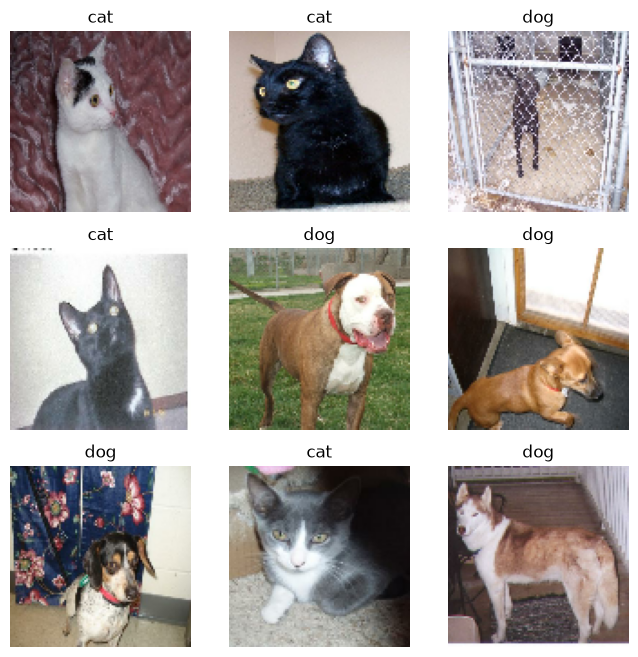

In [8]:
## Check if the above manipulation worked with some training datasets

class_names = ["cat", "dog"]          ## label 0 = cat, label 1 = dog

for images, labels in train_ds.take(1):        ## take one batch
    print("Image batch shape:", images.shape)  ## Prints out the shape of the images 
    print("Image dtype:", images.dtype)        ## Prints out the datatype of the images
    print("Labels:", labels.numpy())           ## Prints out the label of the images

    plt.figure(figsize=(8, 8))
    for i in range(9):                          ## how many images in a 3 x 3 grid?
        plt.subplot(3, 3, i + 1)                   ## position in the grid (counts from 1)
        plt.imshow(images[i].numpy())              ## show image number i
        plt.title(class_names[int(labels[i])])     ## turn 0/1 into "cat"/"dog"
        plt.axis("off")
    plt.show()

In [9]:
## Baseline 1: always predict the most common class in the training set
majority = train_df["label"].mode()[0]                  ## Find the most common label (0 = cat, 1 = dog)
majority_acc = (test_df["label"] == majority).mean()    ## The fraction of test images whose true label is the majority class, which is the baseline’s accuracy

results = {"Majority class": majority_acc} ## Save the model result
print("Most common training label:", majority)  ## Print the result
print(results)

Most common training label: 0
{'Majority class': np.float64(0.5017074558907229)}


In [10]:
## Baseline 2 (preparation): turn images into small grayscale arrays
SMALL = 32

def load_small(path, label):
    img = tf.io.read_file(path)                          ## Read the files through the given path
    img = tf.io.decode_jpeg(img, channels=3)             ## Decode each image as colour (RGB)
    img = tf.image.rgb_to_grayscale(img)                 ## Changes the colour of images to gray scale
    img = tf.image.resize(img, (SMALL, SMALL)) / 255.0   ## Shrink to 32x32, and scale images to 0-1
    return tf.reshape(img, [-1]), label                  ## Flatten the images to one row

def to_arrays(df):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values)) ## One element per image: a (path, label) pair from each row of the table
    ds = ds.map(load_small, num_parallel_calls=AUTO).batch(512) ## loads images in parallel in batches of 512
    X, y = [], []     ## Iniliatlise the empty lists
    for xb, yb in ds:
        X.append(xb.numpy())     ## Converts from TensorFLow to NumPy arrays 
        y.append(yb.numpy())
    return np.concatenate(X), np.concatenate(y) ## Joins the batches into a table: X has one row per image and y has the labels 

X_train_small, y_train_small = to_arrays(train_df.sample(4000, random_state=seed)) ## Randomly choose 4000 images from the training dataset
X_test_small, y_test_small = to_arrays(test_df)   ## A full dataset to test

print(X_train_small.shape, X_test_small.shape)

(4000, 1024) (3514, 1024)


In [11]:
## Baseline 2: logistic regression on small grayscale images
from sklearn.linear_model import LogisticRegression  ## Import the logistic regression module from Scikit-learn
from sklearn.metrics import accuracy_score   ## Import accuray score from from Scikit-learn

logreg = LogisticRegression(max_iter=1000)  ## Max intertaion for the regression to converge
logreg.fit(X_train_small, y_train_small)    ## Learn from the training arrays

y_pred_small = logreg.predict(X_test_small)               ## Predict the test images
logreg_acc = accuracy_score(y_test_small, y_pred_small)   ## Compare with the true test labels

results["Logistic regression"] = logreg_acc   ## Save the regression result
print(results)                                ## Print from the regression result

{'Majority class': np.float64(0.5017074558907229), 'Logistic regression': 0.5318725099601593}


Image batch shape: (32, 100, 100, 3)
Image dtype: <dtype: 'uint8'>
Labels: [1 0 0 1 1 1 1 1 0 1 0 0 0 1 0 0 0 1 0 1 0 1 1 1 1 0 0 1 0 1 1 0]


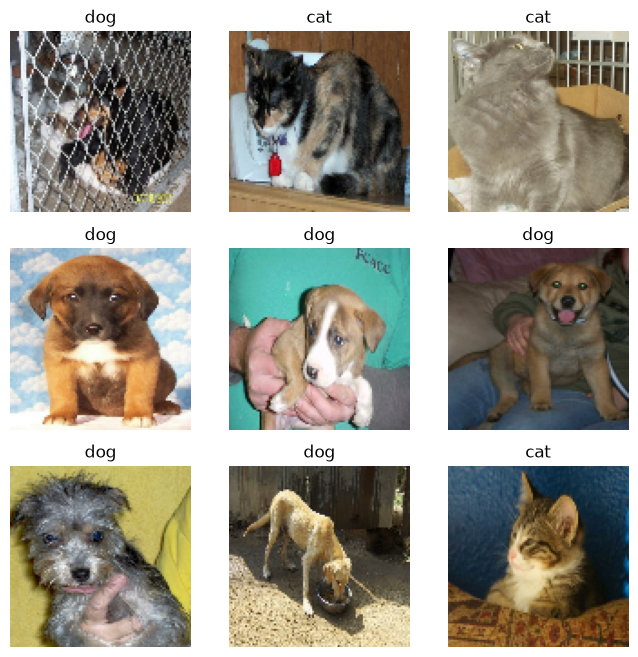

In [12]:
## Check if above manipulation worked with some training datasets
class_names = ["cat", "dog"]          ## label 0 = cat, label 1 = dog

for images, labels in train_ds.take(1):        ## Take one batch of the data
    print("Image batch shape:", images.shape)  ## Print the batch shape
    print("Image dtype:", images.dtype)        ## Print the data type
    print("Labels:", labels.numpy())           ## Print the data labels

    plt.figure(figsize=(8, 8))                ## Plot the results
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
    plt.show()

In [13]:
##  Build the CNN model
from tensorflow.keras import layers, models   ## Import layers and models from TensorFlow

model = models.Sequential([                      ## Sequemtial: single input, single output model
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)), ## Input the image size 
    layers.Rescaling(1./255),                    ## Pixels 0-255 -> 0-1

    layers.Conv2D(32, 3, activation="relu"),     ## 2D Convolution layer with 32 filters, 3 kernel size, activation function is rectified linear unit 
    layers.BatchNormalization(),                 ## Normalises the input
    layers.MaxPooling2D(2),                      ## Downsamples the input along its spatial dimensions by taking the max. value over an input window
    layers.Dropout(0.25),                        ## Dropout rate of 25% to reduce overfitting

    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    ## Layers to combine output from convolution blocks and output a pribability
    layers.Flatten(),                         ## Turns the 3D feature map into a row of numbers per image    
    layers.Dense(512, activation="relu"),     ## One fully connected layer with 512 neurons. This is the important one to fix. 
    layers.BatchNormalization(),              ## Normalisation to keep the training stable 
    layers.Dropout(0.5),                      ## Drop out to reduce overfitting
    layers.Dense(2, activation="softmax"),    ## 2 neurons for each option, softmax turns it into probabilities
])

In [14]:
## Compile the CNN model and inspect it
model.compile(                                 ## Configuring the model for training
    optimizer="rmsprop",                       ## Using RMSprop to maintain a moving average of the square of gradients divide gradinet by the square root of this average 
    loss="sparse_categorical_crossentropy",    ## Computes the crossentropy loss between the labels and predictions
    metrics=["accuracy"],                      ## Accuracy matches the fraction of images where the class with the highest probability matches the true label
)

model.summary()                                ## Lists all layers, output shape and numver of parameters

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 100, 100, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 98, 98, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 98, 98, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 49, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 49, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 47, 47, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 47, 47, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 23, 23, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 23, 23, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 21, 21, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 21, 21, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 10, 10, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 10, 10, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12800)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       6,554,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │           1,026 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,651,330 (25.37 MB)

 Trainable params: 6,649,858 (25.37 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [15]:
## Callbacks: stop early and lower the learning rate when progress stalls

early_stop = tf.keras.callbacks.EarlyStopping(    ## Stop training when a monitored paramter has stopped improving
    monitor= "val_loss",               ## Specify the monitor as the validation loss
    patience=5,                        ## Number of epochs with no improvements after which training will be stopped
    restore_best_weights=True,         ## Restores model weights from the epoch with the best value of the monitored quantity
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(   ## Reduce the learning rate when the matric has stopped improving
    monitor= "val_accuracy",    ## Specify the monitor as the validation ACCURACY
    patience=2,                 ## After 2 epochs with no improvement in validation accuracy
    factor=0.5,                 ## Factor by which learning rate is halved
    min_lr=1e-5,                ## Lower bound of the learning rate
    verbose=1,                  ## Print a message when it happens
)

callbacks = [early_stop, reduce_lr]   ## Specify the list of the callbacks 

In [16]:
## Train the CNN model
history = model.fit(                 ## Trains the model for fixed number of epochs
       train_ds,                     ## Input the training dataset
       validation_data= val_ds,      ## Input the validation data to evaluate loss
       epochs=30,                    ## Number of epochs to train the model
       callbacks=callbacks,          ## List of the callbacks
)

Epoch 1/30


C:\Users\684536\AppData\Local\anaconda3\envs\cnn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


513/513 ━━━━━━━━━━━━━━━━━━━━ 381s 735ms/step - accuracy: 0.6690 - loss: 0.7315 - val_accuracy: 0.5112 - val_loss: 2.1110 - learning_rate: 0.0010
Epoch 2/30
513/513 ━━━━━━━━━━━━━━━━━━━━ 409s 798ms/step - accuracy: 0.7608 - loss: 0.5029 - val_accuracy: 0.6798 - val_loss: 0.6861 - learning_rate: 0.0010
Epoch 3/30
513/513 ━━━━━━━━━━━━━━━━━━━━ 364s 709ms/step - accuracy: 0.7958 - loss: 0.4420 - val_accuracy: 0.5761 - val_loss: 1.3787 - learning_rate: 0.0010
Epoch 4/30
513/513 ━━━━━━━━━━━━━━━━━━━━ 370s 720ms/step - accuracy: 0.8262 - loss: 0.3917 - val_accuracy: 0.8147 - val_loss: 0.4455 - learning_rate: 0.0010
Epoch 5/30
513/513 ━━━━━━━━━━━━━━━━━━━━ 386s 751ms/step - accuracy: 0.8487 - loss: 0.3495 - val_accuracy: 0.8275 - val_loss: 0.3761 - learning_rate: 0.0010
Epoch 6/30
513/513 ━━━━━━━━━━━━━━━━━━━━ 382s 744ms/step - accuracy: 0.8680 - loss: 0.3084 - val_accuracy: 0.7037 - val_loss: 0.6749 - learning_rate: 0.0010
Epoch 7/30
513/513 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - accuracy: 0.8805 - 

In [17]:
## Save the trained model for later use
model.save("cnn_original.keras")

In [18]:
test_loss, test_acc = model.evaluate(test_ds)  ## Evaluates the CNN model with the test dataset, returning test loss and test accuracy
results["CNN (original)"] = test_acc          ## Adds the models score
print(results)                                ## Prints the results

110/110 ━━━━━━━━━━━━━━━━━━━━ 18s 163ms/step - accuracy: 0.8845 - loss: 0.3450
{'Majority class': np.float64(0.5017074558907229), 'Logistic regression': 0.5318725099601593, 'CNN (original)': 0.8844621777534485}


110/110 ━━━━━━━━━━━━━━━━━━━━ 14s 122ms/step


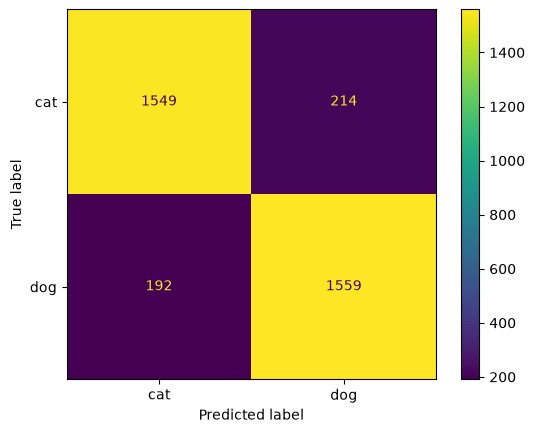

              precision    recall  f1-score   support

         cat       0.89      0.88      0.88      1763
         dog       0.88      0.89      0.88      1751

    accuracy                           0.88      3514
   macro avg       0.88      0.88      0.88      3514
weighted avg       0.88      0.88      0.88      3514



In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report  ## Confusion matrix to evaluate the accuracy of a classification
                                                                                             ## ConfusionMatrixDisplay to display the Confusion matrix
                                                                                             ## classification_report builds a text report showing the main classification metrics    
y_prob = model.predict(test_ds)       ## Finds the probabilities for cat and dog, one row per image
y_pred = y_prob.argmax(axis=1)        ## Finds the class with the higher probability
y_true = test_df["label"].values      ## test_ds is not shuffled, so the order matches

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot() ## Makes the confusion matrix display
plt.show()   ## Plots the confusion matrix 
print(classification_report(y_true, y_pred, target_names=class_names))   ## Prints precision, recall and F1 for each class

In [20]:
## Compare all models on the test set, with uncertainty
n_test = len(test_df)    ## Find length of the test dataset

table = pd.DataFrame({"Test accuracy": results})     ## Table to display the accuracy and 
table["Std error"] = np.sqrt(table["Test accuracy"] * (1 - table["Test accuracy"]) / n_test)  ## Calculate the standard error for each method
table = (table * 100).round(1)          ## Show the accuracy and error as percentages
print(table)                            ## Print the table 

                     Test accuracy  Std error
Majority class                50.2        0.8
Logistic regression           53.2        0.8
CNN (original)                88.4        0.5


406 misclassified test images


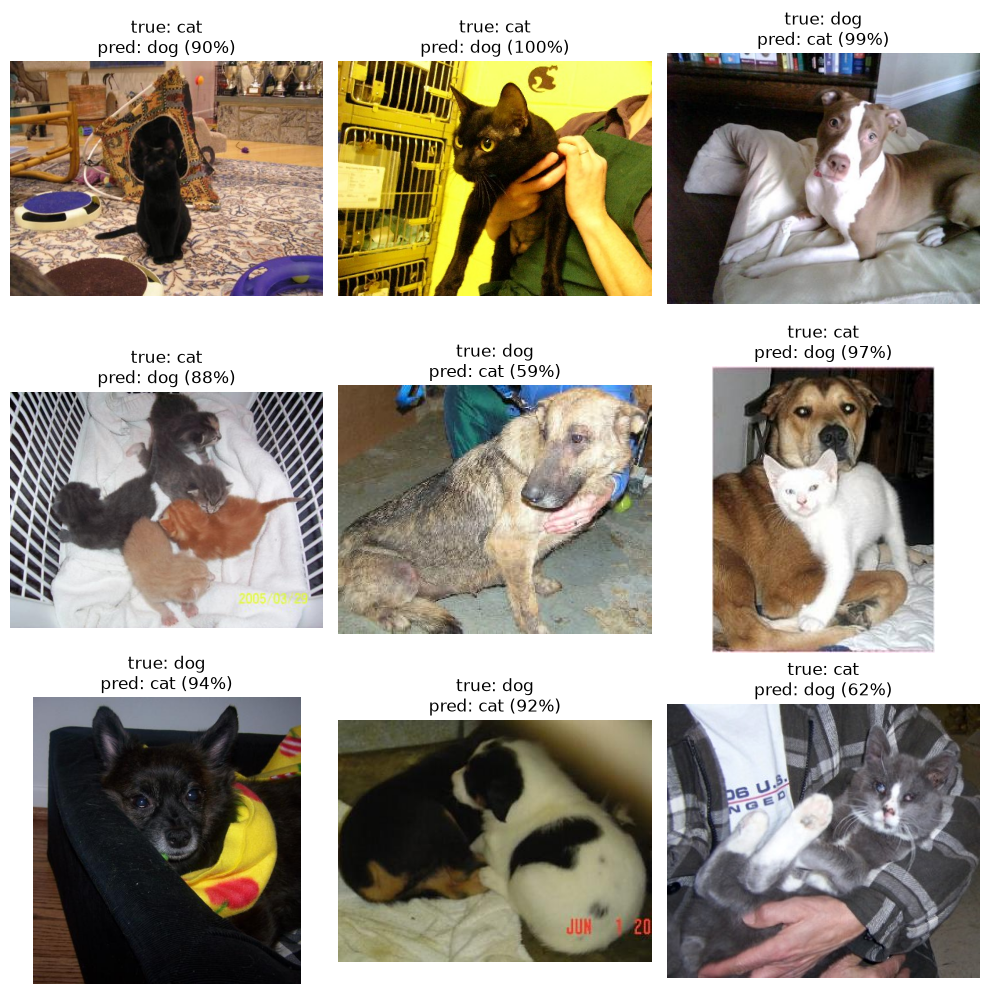

In [21]:
## Look at some misclassified test images
wrong = np.where(y_pred != y_true)[0]               ## Finds the wrongly classified images
print(len(wrong), "misclassified test images")      ## Prints the number of misclassified images

plt.figure(figsize=(10, 10))
for k, idx in enumerate(wrong[:9]):                 ## Shows the first 9 misclassified images
    plt.subplot(3, 3, k + 1)                        ## Makes subplots of 3 x 3
    plt.imshow(plt.imread(test_df["path"].values[idx]))
    plt.title(f"true: {class_names[y_true[idx]]}\n"
              f"pred: {class_names[y_pred[idx]]} ({y_prob[idx].max():.0%})")  ## Prints the title with true and prediction labels with prediction %.
    plt.axis("off")
plt.tight_layout()
plt.show()

In [22]:
## Reload the trained model

model = tf.keras.models.load_model("cnn_original.keras")   ## Reloads the model
test_loss, test_acc = model.evaluate(test_ds)              ## Evaluates the model and finds the test accuracy and loss
print(f"Test accuracy: {test_acc: .3f}")                   ## Print the test accuracy. 

110/110 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.8845 - loss: 0.3450
Test accuracy:  0.884


In [23]:
## Grad-CAM to understand which part of images pushed towards the results

def make_gradcam_heatmap(img, model, conv_layer_name = "conv2d_2"):      ## Pass the images, model and the convolution layers as function input
    x = tf.cast(img[None, ...], tf.float32) ## one image -> a batch of one
    with tf.GradientTape() as tape:
        conv_out = None
        for layer in model.layers:  ## run the image through layer by layer 
            x = layer(x, training = False)
            if layer.name == conv_layer_name:
                conv_out = x        ## keep the last conv layer's output
                tape.watch(conv_out)
        preds = x                     ## final probabilities [cat, dog]
        pred_idx = int(tf.argmax(preds[0]))
        class_score = preds[:, pred_idx]
        
    grads = tape.gradient(class_score, conv_out)               ## importance of each detector, at each position
    weights = tf.reduce_mean(grads, axis = (0, 1, 2))          ## average importance per detector (128 numbers)
    heatmap = tf.reduce_sum(conv_out[0] * weights, axis = -1)  ## weighted sum -> 21 x 21 map
    heatmap = tf.nn.relu(heatmap)                              ## keep only positive evidence
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)         ## scale to 0-1
    return heatmap.numpy(), pred_idx, float(preds[0, pred_idx])   ## Return the heat map as a NumPy array

In [24]:
## Test to check one image and the heatmap

class_names = ["cat", "dog"]                 ## Initialise the labels
def show_gradcam(idx, ax):
    path, label = test_df["path"].values[idx], test_df["label"].values[idx]   ## Initialise the path and label of the test datset
    img, _ = load_image(path, label)                                          ## Load the image  
    heatmap, pred_idx, conf = make_gradcam_heatmap(img, model)                ## Function call to make the heat map
    heatmap = tf.image.resize(heatmap[..., None], (IMG_SIZE, IMG_SIZE))[..., 0]   ## resizing the heat map
    ax.imshow(img.numpy())                                             
    ax.imshow(heatmap, cmap = "jet", alpha = 0.4)                       ## Plotting the heat map
    ax.set_title(f"true: {class_names[label]} | pred: {class_names[pred_idx]} ({conf:.0%})")   ## Setting the title of the heat map
    ax.axis("off")

In [25]:
## Predictions on the test set and which ones are right or wrong
y_prob = model.predict(test_ds)        ## Make predictions on the test dataset
y_pred = y_prob.argmax(axis = 1)       ## Get the predictions
y_true = test_df["label"].values       ## Get the test dataset labels

correct = np.where(y_pred == y_true)[0]   ## Findings the correctly predicted images
wrong = np.where(y_pred != y_true)[0]     ## Findings the wrongly predicted images
print(len(correct), "correct", len(wrong), "wrong") ## Printing the number of correctly and wrongly predicted images

110/110 ━━━━━━━━━━━━━━━━━━━━ 14s 128ms/step
3108 correct 406 wrong


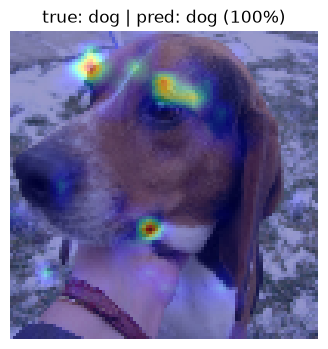

In [26]:
## Run the test to check one image and the heatmap

fig, ax = plt.subplots(figsize = (4, 4))  ## Plot the heatmap
show_gradcam(correct[0], ax)  
plt.show()

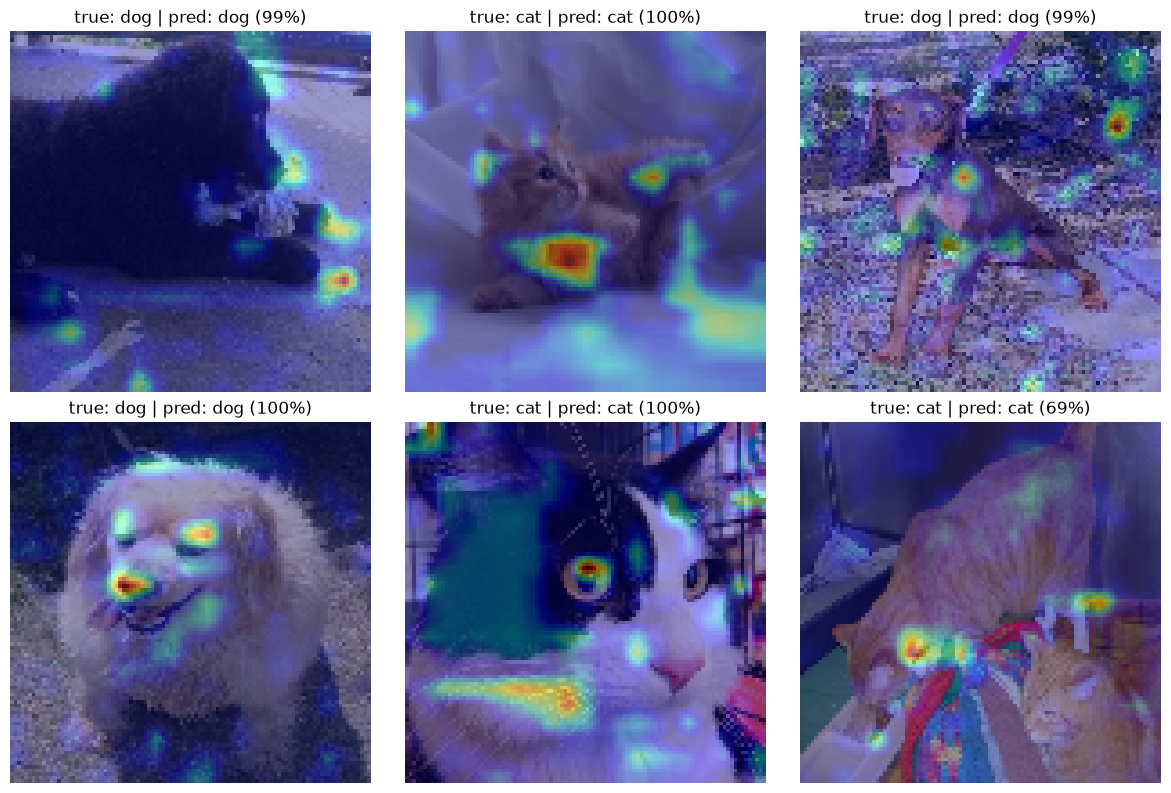

In [27]:
## Plot heatmaps of a few correctly predicted images

rng = np.random.default_rng(seed)                     ## Repeatable random picks
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, idx in zip(axes.flat, rng.choice(correct, 6, replace=False)):  ## Plotting heatmap of 6 correctly predicted images
    show_gradcam(idx, ax)            ## Fuction call to show gradcam
plt.tight_layout()
plt.show()

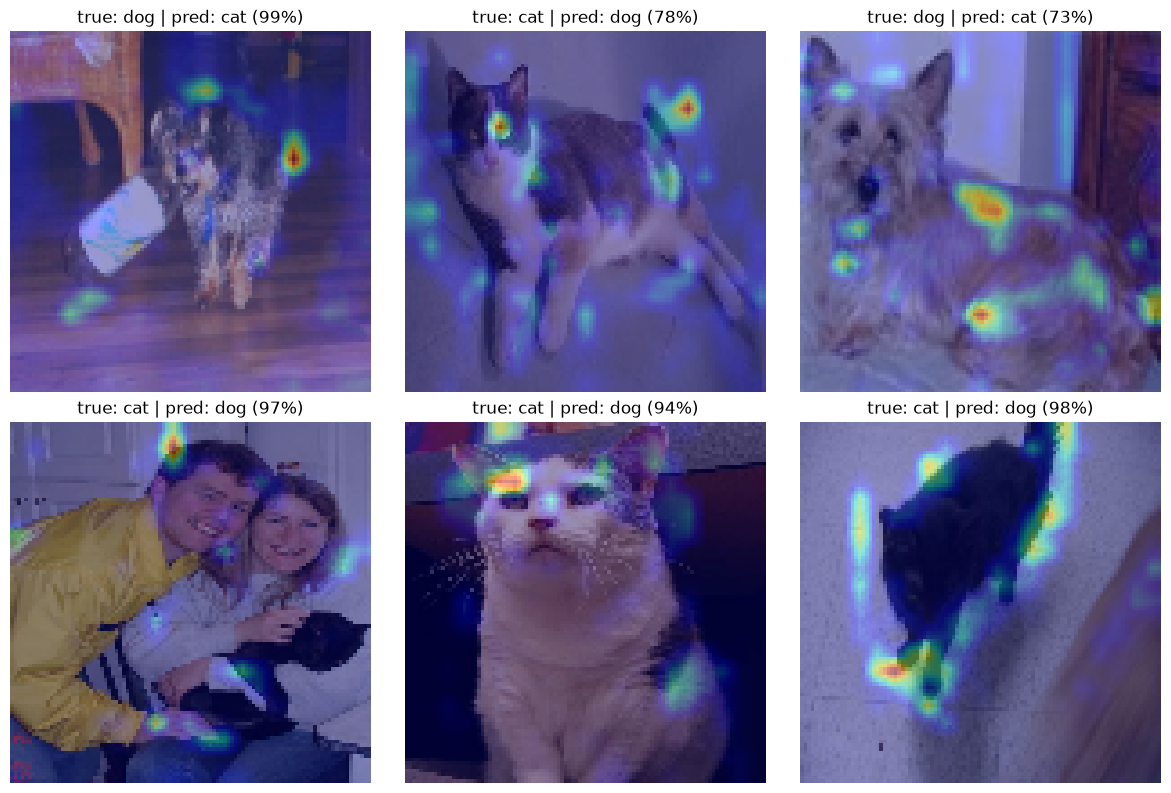

In [28]:
## Plot heatmaps of a few wrongly predicted images

rng = np.random.default_rng(seed)                     # Repeatable random picks
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, idx in zip(axes.flat, rng.choice(wrong, 6, replace=False)):    ## Plotting heatmap of 6 wrongly predicted images
    show_gradcam(idx, ax)    ## Fuction call to show gradcam
plt.tight_layout()
plt.show()

In [29]:
## Robustness test: how does accuracy chnage when test images are altered?

def evaluate_with(transform, name):       ## Robustness evaluation function with transformation and the type of transformation
    ds = test_ds.map(lambda x, y : (transform(x), y))   ## Build a new data set based on the transformation  
    _, acc = model.evaluate(ds, verbose = 0)         ## Evaluate the model bases on the new dataset
    print(f"{name:25s} {acc:.3f}")              ## Print the accurcay for each of the changed cases 
    return acc

shift_results = {} 
shift_results["Original"]            = evaluate_with(lambda x: x, "Original")     ## Keep the image and original 
shift_results["Mirrored"]            = evaluate_with(lambda x: tf.image.flip_left_right(x), "Mirrored (left-right)")  ## Flips the original image
shift_results["Darker (50%)"]        = evaluate_with(lambda x: tf.cast(tf.cast(x, tf.float32) * 0.5, tf.uint8), "Darker (50% Brightness)")   ## Makes the images darker by 50%
shift_results["Greyscale"]           = evaluate_with(lambda x: tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x)), "Grayscale") ## Changes from RGB to grayscale
shift_results["Rotated 90 degree"]   = evaluate_with(lambda x: tf.image.rot90(x), "Rotated 90- degrees")   ## Rotates the images by 90 degree
shift_results["Upside down"]         = evaluate_with(lambda x: tf.image.flip_up_down(x), "Upside down")   ## Flips the images up side down

Original                  0.884
Mirrored (left-right)     0.882
Darker (50% Brightness)   0.843
Grayscale                 0.870
Rotated 90- degrees       0.721
Upside down               0.633


In [30]:
## Load any image for the new dataset to test the model

IMG_SIZE = 100
def load_any_image(path):         ## Pass the file path as the function argument
    img = tf.io.read_file(path)   ## Read the file
    img = tf.io.decode_image(img, channels  = 3, expand_animations = False)  ## Decode the image file
    img = tf.image.resize(img, (IMG_SIZE , IMG_SIZE))   ## Resize the image
    img = tf.cast(img, tf.uint8)   ## cast the image as TensorFlow unit8
    return img                    ## return the image


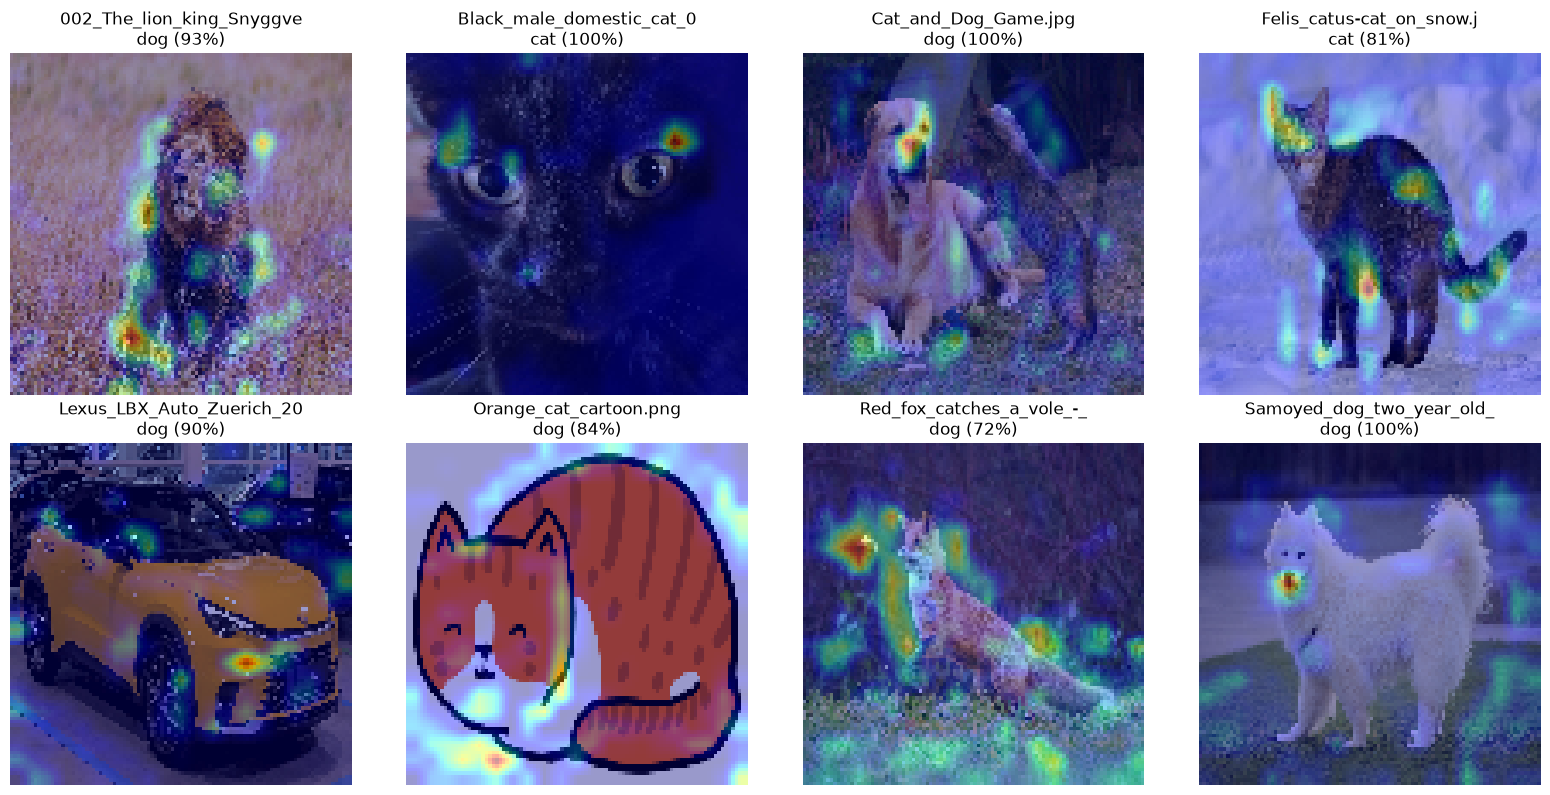

In [31]:
## Predict using Grad-CAM
test_folder = r"C:\Users\684536\OneDrive - hull.ac.uk\my_tests"    ## Specify the path to the new dataset

files = sorted(f for f in os.listdir(test_folder) if f.lower().endswith((".jpg", ".jpeg", ".png")))   ## Sort the dateset

#print(files)

cols = 4
rows = (len(files) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize = (4 * cols, 4 * rows))
axes = axes.flatten()

for ax, fname in zip(axes, files):
    img = load_any_image(os.path.join(test_folder, fname))    ## Load the images for the folder
    heatmap, pred_idx, conf = make_gradcam_heatmap( img, model)    ## Make the heatmap of the new dataset with the model by calling the heatmap maker function
    heatmap = tf.image.resize(heatmap[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    ax.imshow(img.numpy())
    ax.imshow(heatmap, cmap = "jet", alpha = 0.4)           ## Show the heat map
    ax.set_title(f"{fname[:25]}\n{class_names[pred_idx]} ({conf:.0%})")   ## Print the title of the images
    ax.axis("off")

for ax in axes[len(files):]:
    ax.axis('off')
plt.tight_layout()
plt.show()


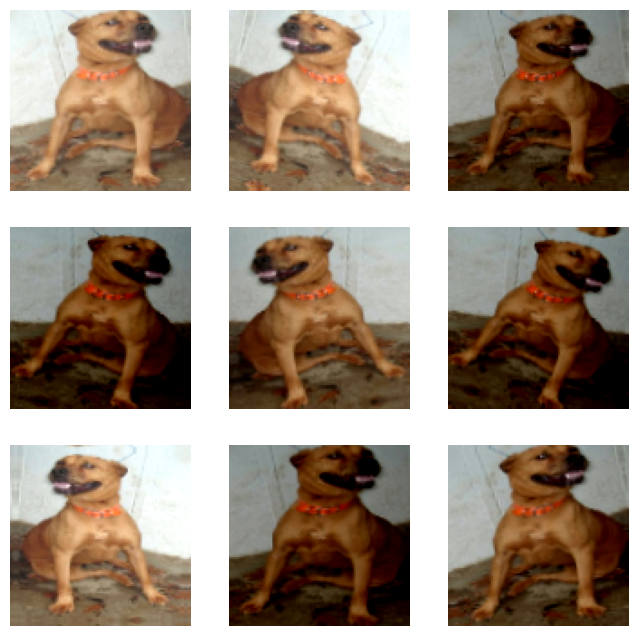

In [32]:
## Define the augmentation and check it works
data_augmentation = tf.keras.Sequential([               ## Define the type of layers
        tf.keras.layers.RandomFlip("horizontal"),       ## Mirrors the images left to right
        tf.keras.layers.RandomRotation(0.05),           ## Tilts the images
        tf.keras.layers.RandomZoom(0.1),                ## Zooms in or out upto 10%
        tf.keras.layers.RandomBrightness(0.3),          ## Makes the images lighter or darker upto 30%
        tf.keras.layers.RandomContrast(0.2),            ## Increases or decreases the contrast upto 20%
], name = "augmentation")

images, labels = next(iter(train_ds))       ## Takes first batch for the training dataset and their labels
img = tf.cast(images[:1], tf.float32)

plt.figure(figsize = (8,8))
for i in range(9):
    aug = data_augmentation(img, training = True)  ## Switches the random changes on; nothing is trained here
    plt.subplot(3, 3, i + 1)
    plt.imshow(aug[0].numpy() / 255)  ## A augmented sets of the same image 
    plt.axis("off")
plt.show()

In [33]:
## Build the new CNN model and train with the augmented data set
from tensorflow.keras import layers, models

model_aug = tf.keras.Sequential([
    tf.keras.Input(shape = (IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,
    tf.keras.layers.Rescaling(1/255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(2, activation="softmax"),         # 2 outputs: probability of cat, dog
])

model_aug.compile(optimizer = "rmsprop", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])
model_aug.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)            │ (None, 100, 100, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 100, 100, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 98, 98, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 98, 98, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 49, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 49, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 47, 47, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 47, 47, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 23, 23, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 23, 23, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 21, 21, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 21, 21, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 10, 10, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 10, 10, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 12800)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 512)                 │       6,554,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 2)                   │           1,026 │
└──────────────────────────────────────┴─────────────────────────────┴──────────────

 Total params: 6,651,330 (25.37 MB)

 Trainable params: 6,649,858 (25.37 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [34]:
## Train the model, monitor validation loss and accuracy loss, reduced learnibf rate and the logger

early_stop_aug = tf.keras.callbacks.EarlyStopping(monitor = "val_loss", patience = 5, restore_best_weights = True)
reduce_lr_avg =  tf.keras.callbacks.ReduceLROnPlateau(monitor = "val_accuracy", patience = 2, factor = 0.5, min_lr = 1e-5, verbose = 1)
checkpoint =  tf.keras.callbacks.ModelCheckpoint("cnn_augmented.keras", monitor = "val_loss", save_best_only = True)
logger =  tf.keras.callbacks.CSVLogger("history_augmented.csv")

history_aug = model_aug.fit(train_ds, validation_data = val_ds, epochs = 40, callbacks = [early_stop_aug, reduce_lr_avg, checkpoint, logger]) ## Train the model with training dataset and validation dataset

Epoch 1/40


C:\Users\684536\AppData\Local\anaconda3\envs\cnn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


513/513 ━━━━━━━━━━━━━━━━━━━━ 459s 889ms/step - accuracy: 0.6063 - loss: 0.8539 - val_accuracy: 0.5887 - val_loss: 0.7323 - learning_rate: 0.0010
Epoch 2/40
513/513 ━━━━━━━━━━━━━━━━━━━━ 459s 893ms/step - accuracy: 0.7020 - loss: 0.5787 - val_accuracy: 0.7563 - val_loss: 0.5246 - learning_rate: 0.0010
Epoch 3/40
513/513 ━━━━━━━━━━━━━━━━━━━━ 438s 854ms/step - accuracy: 0.7449 - loss: 0.5219 - val_accuracy: 0.7233 - val_loss: 0.6030 - learning_rate: 0.0010
Epoch 4/40
513/513 ━━━━━━━━━━━━━━━━━━━━ 0s 846ms/step - accuracy: 0.7707 - loss: 0.4825
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
513/513 ━━━━━━━━━━━━━━━━━━━━ 446s 870ms/step - accuracy: 0.7707 - loss: 0.4825 - val_accuracy: 0.7526 - val_loss: 0.5908 - learning_rate: 0.0010
Epoch 5/40
513/513 ━━━━━━━━━━━━━━━━━━━━ 463s 902ms/step - accuracy: 0.8005 - loss: 0.4354 - val_accuracy: 0.7859 - val_loss: 0.5139 - learning_rate: 5.0000e-04
Epoch 6/40
513/513 ━━━━━━━━━━━━━━━━━━━━ 457s 890ms/step - accuracy: 0.8082

In [35]:
model_aug = tf.keras.models.load_model("cnn_augmented.keras")   # best epoch (14), saved by the checkpoint
test_loss_aug, test_acc_aug = model_aug.evaluate(test_ds)
results["CNN (augmented)"] = test_acc_aug
print(results)

transforms = {
    "Original":     lambda x: x,
    "Mirrored":     lambda x: tf.image.flip_left_right(x),
    "Darker (50%)": lambda x: tf.cast(tf.cast(x, tf.float32) * 0.5, tf.uint8),
    "Greyscale":    lambda x: tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x)),
    "Rotated 90":   lambda x: tf.image.rot90(x),
    "Upside down":  lambda x: tf.image.flip_up_down(x),
}
rows = {}
for name, t in transforms.items():
    ds = test_ds.map(lambda x, y: (t(x), y))
    _, acc_orig = model.evaluate(ds, verbose=0)
    _, acc_aug = model_aug.evaluate(ds, verbose=0)
    rows[name] = {"Original CNN": acc_orig, "Augmented CNN": acc_aug}
print((pd.DataFrame(rows).T * 100).round(1))

110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 89ms/step - accuracy: 0.8890 - loss: 0.2825
{'Majority class': np.float64(0.5017074558907229), 'Logistic regression': 0.5318725099601593, 'CNN (original)': 0.8844621777534485, 'CNN (augmented)': 0.8890153765678406}
              Original CNN  Augmented CNN
Original              88.4           88.9
Mirrored              88.2           88.6
Darker (50%)          84.3           86.0
Greyscale             87.0           85.8
Rotated 90            72.1           73.2
Upside down           63.3           65.0
